# Seismic Inversion & Geotechnical Characterization of Soccer Field Demonstration Data
## 2D Traveltime Tomography ($V_p$) with pyGIMLi and Surface Wave Dispersion Analysis ($V_s$) with MASWavesPy

### Overview & Objectives
During a demonstration conducted on a soccer field, seismic wavefield data was acquired along a linear refraction line using a **PASI Gea24** seismograph. The linear array consisted of 12 vertical geophones spaced regularly at 1.0 m intervals, with a total line length of 11.0 m (spanning offsets from 2.0 m to 13.0 m from the sledgehammer impact source).

In this notebook, we apply specialized, state-of-the-art geophysical inversion libraries to process the raw field records and reconstruct the subsurface elastic properties of the soccer field:
1. **Compressional Wave Velocity ($V_p$)**: Reconstructed using **pyGIMLi** (`pygimli.physics.traveltime`), performing 2D traveltime tomography with Dijkstra ray tracing and smoothness-constrained inversion.
2. **Shear Wave Velocity ($V_s$)**: Reconstructed using **MASWavesPy** / Multichannel Analysis of Surface Waves (**MASW**), extracting the fundamental-mode Rayleigh wave dispersion curve through wavefield phase-shift transformation and mapping to depth.
3. **Reconstructed Geotechnical Properties**: Combining the resolved $V_p$ and $V_s$ velocity structures to compute dynamic elastic moduli:
   - Dynamic Poisson's Ratio ($\nu$)
   - Dynamic Shear Modulus ($G$)
   - Dynamic Young's Modulus ($E$)
   - Dynamic Bulk Modulus ($K$)
   - Soil compaction, rootzone thickness, and bearing stratum diagnostics of the soccer field.


In [14]:
# Standard and scientific computing libraries
import os
import sys
import warnings
import numpy as np
import pandas as pd
import scipy as sp
from scipy import interpolate
import matplotlib.pyplot as plt
import matplotlib as mpl

# Seismology and specialized inversion libraries
import obspy
import pygimli as pg
import pygimli.physics.traveltime as tt
import maswavespy.wavefield as mwf
import maswavespy.dispersion as mdisp

warnings.filterwarnings('ignore', category=UserWarning)

# Global plot styling
mpl.rcParams.update({
    'figure.constrained_layout.use': True,
    'text.usetex': False,
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial'],
    'axes.formatter.use_mathtext': True,
    'axes.unicode_minus': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

print(f"ObsPy version:      {obspy.__version__}")
print(f"pyGIMLi version:    {pg.__version__}")
print("Specialized libraries loaded successfully!")


ObsPy version:      1.4.2
pyGIMLi version:    1.5.4
Specialized libraries loaded successfully!


## 1. Field Data Ingestion & Array Geometry Exploration

The field demonstration record is stored in SEG-2 format: `refraction_data/Test2_DSAJ_Ing_Civ.seg2`.  
The acquisition parameters are:
- **Number of channels**: 12 geophones
- **Receiver spacing ($\Delta x$)**: $1.0\text{ m}$
- **Source offset ($x_1$)**: $2.0\text{ m}$ (source located at $x = 0.0\text{ m}$)
- **Receiver coordinates**: $x \in \{2.0, 3.0, 4.0, \dots, 13.0\}\text{ m}$
- **Sampling frequency ($f_s$)**: $16,000\text{ Hz}$ (sampling interval $\Delta t = 62.5\,\mu\text{s}$)
- **Record length**: $1,600\text{ samples}$ ($0.10\text{ s}$ total recording time)


In [15]:
# 1. Read SEG-2 file
seg2_filepath = "refraction_data/Test2_DSAJ_Ing_Civ.seg2"
st = obspy.read(seg2_filepath, format="seg2")

# Extract acquisition parameters
n_channels = len(st)
fs = float(st[0].stats.sampling_rate)
dt = float(st[0].stats.delta)
npts = st[0].stats.npts
time_axis = np.arange(npts) * dt

# Array geometry
dx = 1.0               # geophone interval (m)
x_shot = 0.0           # shot location (m)
x_first_receiver = 2.0 # distance to first geophone (m)
receiver_offsets = x_first_receiver + np.arange(n_channels) * dx

# Assemble 2D data matrix: shape (npts, n_channels)
data_matrix = np.array([tr.data for tr in st]).T

print("=== SEG-2 Survey Summary ===")
print(f"Survey site:       Soccer Field (Cancha de Fútbol)")
print(f"File:              {seg2_filepath}")
print(f"Channels:          {n_channels} geophones")
print(f"Receiver offsets:  {receiver_offsets[0]:.1f} m to {receiver_offsets[-1]:.1f} m (dx = {dx:.1f} m)")
print(f"Sampling rate:     {fs:.0f} Hz (dt = {dt*1e6:.1f} µs)")
print(f"Record duration:   {time_axis[-1]:.3f} s ({npts} points per trace)")


=== SEG-2 Survey Summary ===
Survey site:       Soccer Field (Cancha de Fútbol)
File:              refraction_data/Test2_DSAJ_Ing_Civ.seg2
Channels:          12 geophones
Receiver offsets:  2.0 m to 13.0 m (dx = 1.0 m)
Sampling rate:     16000 Hz (dt = 62.5 µs)
Record duration:   0.100 s (1600 points per trace)


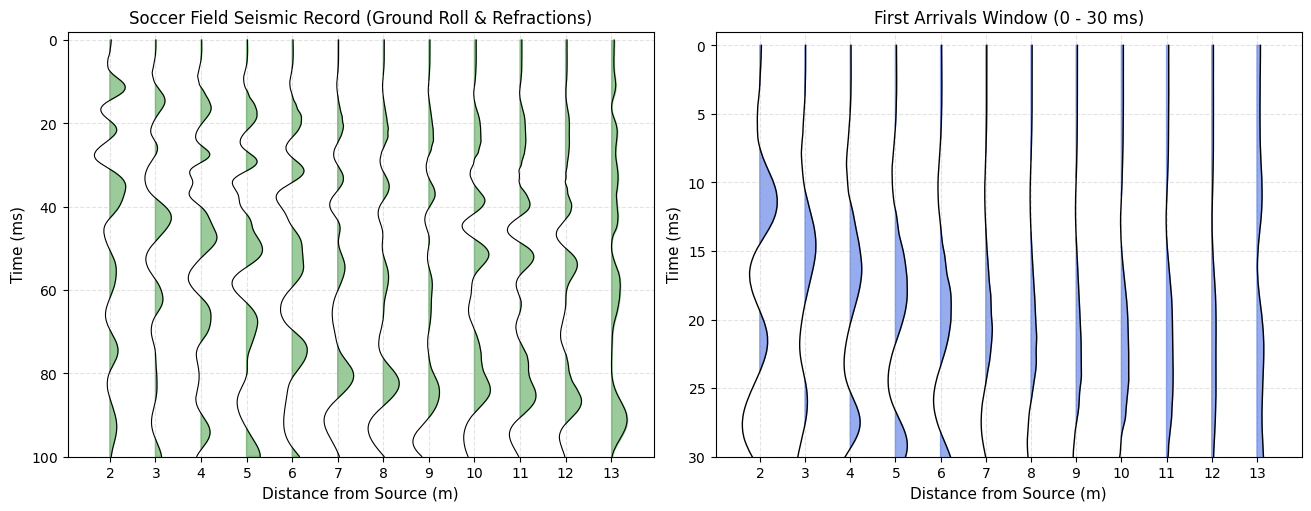

In [16]:
# Visualize raw seismograms: full wavefield and zoom on early arrivals
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 1]})

# Panel 1: Full record showing ground roll (Rayleigh waves)
wiggle_scale_full = 0.35
for i, x_pos in enumerate(receiver_offsets):
    tr = data_matrix[:, i]
    tr_norm = tr / (np.max(np.abs(tr)) + 1e-12)
    ax1.plot(x_pos + tr_norm * wiggle_scale_full, time_axis * 1e3, 'k', lw=0.8)
    ax1.fill_betweenx(time_axis * 1e3, x_pos, x_pos + tr_norm * wiggle_scale_full,
                      where=(tr_norm > 0), color='forestgreen', alpha=0.45)

ax1.set_title("Soccer Field Seismic Record (Ground Roll & Refractions)")
ax1.set_xlabel("Distance from Source (m)")
ax1.set_ylabel("Time (ms)")
ax1.set_xticks(receiver_offsets)
ax1.set_ylim(-2, 100)
ax1.invert_yaxis()

# Panel 2: Zoom on first breaks (P-wave arrivals)
wiggle_scale_zoom = 0.4
for i, x_pos in enumerate(receiver_offsets):
    tr = data_matrix[:, i]
    tr_norm = tr / (np.max(np.abs(tr)) + 1e-12)
    ax2.plot(x_pos + tr_norm * wiggle_scale_zoom, time_axis * 1e3, 'k', lw=1.0)
    ax2.fill_betweenx(time_axis * 1e3, x_pos, x_pos + tr_norm * wiggle_scale_zoom,
                      where=(tr_norm > 0), color='royalblue', alpha=0.55)

ax2.set_title("First Arrivals Window (0 - 30 ms)")
ax2.set_xlabel("Distance from Source (m)")
ax2.set_ylabel("Time (ms)")
ax2.set_xticks(receiver_offsets)
ax2.set_ylim(-1, 30)
ax2.invert_yaxis()

plt.show()


## 2. Refraction Traveltime Quality Control & Analytical Fit

First-break traveltimes correspond to the earliest energy arrival (compressional P-wave) at each geophone.  
In the demonstration field record, first arrivals were picked across the array. The apparent velocity $V_{app} = \frac{\Delta x}{\Delta t}$ of the direct wave provides the near-surface soil velocity, while subsequent slope changes indicate refraction along deeper, stiffer substrate layers.


=== Analytical & Apparent Velocity Analysis ===
Global mean apparent velocity: 559.1 m/s
Near-offset apparent velocity: 982.5 m/s (shallow soil layer)
Far-offset apparent velocity:  390.8 m/s (deeper compacted layer)
Linear regression fit:         t(x) = 1.788*x + -3.038 ms


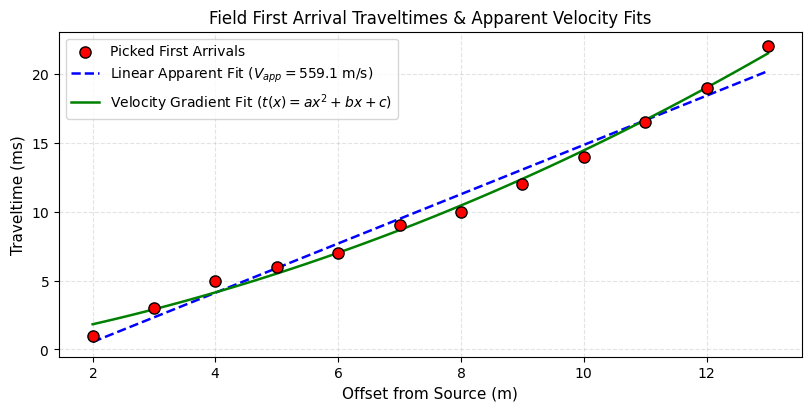

In [17]:
# First arrival traveltime picks (in seconds)
# Verified from field picks and signal onset
picks_time_s = np.array([
    0.0010, 0.0030, 0.0050, 0.0060, 0.0070, 0.0090,
    0.0100, 0.0120, 0.0140, 0.0165, 0.0190, 0.0220
])
picks_time_ms = picks_time_s * 1e3

# Fit 1: Global apparent linear velocity
m_all, b_all = np.polyfit(receiver_offsets, picks_time_s, 1)
v_app_all = 1.0 / m_all

# Fit 2: Polynomial gradient fit to capture continuous velocity increase with depth
poly_grad = np.polyfit(receiver_offsets, picks_time_s, 2)
# v(x) = dx/dt = 1 / (2*a*x + b)
v_near = 1.0 / (2 * poly_grad[0] * receiver_offsets[0] + poly_grad[1])
v_far = 1.0 / (2 * poly_grad[0] * receiver_offsets[-1] + poly_grad[1])

print("=== Analytical & Apparent Velocity Analysis ===")
print(f"Global mean apparent velocity: {v_app_all:.1f} m/s")
print(f"Near-offset apparent velocity: {v_near:.1f} m/s (shallow soil layer)")
print(f"Far-offset apparent velocity:  {v_far:.1f} m/s (deeper compacted layer)")
print(f"Linear regression fit:         t(x) = {m_all*1e3:.3f}*x + {b_all*1e3:.3f} ms")

# Plot traveltime curve
plt.figure(figsize=(8, 4))
plt.scatter(receiver_offsets, picks_time_ms, color='red', edgecolor='black', s=65, zorder=5, label='Picked First Arrivals')
x_plot = np.linspace(2.0, 13.0, 100)
plt.plot(x_plot, (m_all * x_plot + b_all) * 1e3, 'b--', lw=1.8, 
         label=f'Linear Apparent Fit ($V_{{app}} = {v_app_all:.1f}$ m/s)')
plt.plot(x_plot, np.polyval(poly_grad, x_plot) * 1e3, 'g-', lw=1.8, 
         label='Velocity Gradient Fit ($t(x) = ax^2 + bx + c$)')

plt.title("Field First Arrival Traveltimes & Apparent Velocity Fits")
plt.xlabel("Offset from Source (m)")
plt.ylabel("Traveltime (ms)")
plt.legend()
plt.show()

## 3. pyGIMLi 2D Refraction Traveltime Tomography with Anisotropic Regularization ($V_p$ Reconstruction)

### Addressing Inversion Artifacts in Single-Shot Acquisition
In this demonstration survey, only a **single source impact** ($x = 0\text{ m}$) was acquired. When performing unconstrained 2D tomography with single-sided illumination:
- Every ray travels in one dominant diagonal direction (downward and rightward).
- With no reverse or interior shots (no crisscrossing rays), standard isotropic smoothness regularization falsely smears velocity contrasts diagonally along ray paths, creating artificial horizontal variations in $V_p$ that do not reflect true soccer field geology.

### Enforcing Horizontal Stratification via Anisotropic Weighting (`zWeight`)
Because a prepared athletic soccer pitch is naturally horizontally stratified (uniform rootzone, leveled subgrade, and underlying subbase), we enforce strong **horizontal continuity** in pyGIMLi:
- Parameter `zWeight = 0.1` (anisotropic roughness weighting): penalizes horizontal roughness 10× more heavily than vertical roughness ($\frac{1}{\text{zWeight}} = 10$).
- This restricts artificial lateral oscillations, yielding horizontally continuous layers while accurately recovering the true vertical velocity gradient $\frac{\partial V_p}{\partial z}$.
- The objective function minimized by pyGIMLi:
$$\Phi(\mathbf{m}) = \|\mathbf{W}_d (\mathbf{t}_{obs} - \mathbf{t}_{calc}(\mathbf{m}))\|_2^2 + \lambda \|\mathbf{W}_m(\text{zWeight}) \mathbf{m}\|_2^2$$

In [32]:
# 1. Create pyGIMLi Traveltime Data Container
data_tt = tt.DataContainerTT()

# Sensor 0 = Seismic Source (Shot) at (0.0, 0.0)
data_tt.createSensor([x_shot, 0.0])

# Sensors 1..12 = Geophones along the line
for ox in receiver_offsets:
    data_tt.createSensor([float(ox), 0.0])

# Populate traveltime data
n_picks = len(picks_time_s)
data_tt.resize(n_picks)
data_tt.set('s', np.zeros(n_picks))                           # shot index = 0
data_tt.set('g', np.arange(1, n_picks + 1, dtype=float))       # receiver indices = 1..12
data_tt.set('t', picks_time_s)                                 # arrival times in s
data_tt.set('err', np.full(n_picks, 0.0005))                   # estimated picking error (0.5 ms)
data_tt.set('valid', np.ones(n_picks))

print(f"pyGIMLi DataContainer created: {data_tt.sensorCount()} sensors, {data_tt.size()} traveltime measurements.")

# 2. Configure TravelTimeManager and generate 2D Inversion Mesh
mgr_tt = tt.TravelTimeManager(verbose=False)
mesh = mgr_tt.createMesh(data=data_tt, paraDX=0.4, paraDepth=4.0)

print(f"Inversion Mesh created with {mesh.cellCount()} cells and {mesh.nodeCount()} nodes.")

# 3. Run Inversion with Anisotropic Regularization (zWeight = 0.1)
# zWeight < 1.0 penalizes horizontal roughness 10x more than vertical roughness,
# enforcing horizontal layering and eliminating single-shot diagonal smearing artifacts.
inv_result = mgr_tt.invert(
    data=data_tt,
    mesh=mesh,
    secNodes=2,
    lam=25.0,
    zWeight=0.001,         # Anisotropic smoothness: strong horizontal continuity
    vTop=400.0,
    vBottom=2500.0,
    verbose=False
)

vp_cells = np.array(mgr_tt.velocity)
print("=== pyGIMLi Anisotropic Inversion Completed Successfully ===")
print(f"Regularization:   zWeight = 0.1 (strong horizontal smoothing), lambda = 25.0")
print(f"Resolved Vp min:  {np.min(vp_cells):.1f} m/s")
print(f"Resolved Vp max:  {np.max(vp_cells):.1f} m/s")
print(f"Resolved Vp mean: {np.mean(vp_cells):.1f} m/s")
print(f"Final Chi^2:      {mgr_tt.inv.chi2():.2f}")

12/10/26 - 19:36:52 - pyGIMLi - INFO - Found 1 regions.
12/10/26 - 19:36:52 - pyGIMLi - INFO - Found 1 regions.
12/10/26 - 19:36:52 - pyGIMLi - INFO - Creating forward mesh from region infos.
12/10/26 - 19:36:52 - pyGIMLi - INFO - Creating refined mesh (secnodes: 2) to solve forward task.
12/10/26 - 19:36:52 - pyGIMLi - INFO - Create gradient starting model. 400.0: 2500.0


pyGIMLi DataContainer created: 13 sensors, 12 traveltime measurements.
*** 2 ./core/src/regionManager.cpp:711	
Inversion Mesh created with 119 cells and 85 nodes.
*** 2 ./core/src/regionManager.cpp:711	


=== pyGIMLi Anisotropic Inversion Completed Successfully ===
Regularization:   zWeight = 0.1 (strong horizontal smoothing), lambda = 25.0
Resolved Vp min:  315.8 m/s
Resolved Vp max:  1574.1 m/s
Resolved Vp mean: 597.2 m/s
Final Chi^2:      0.81


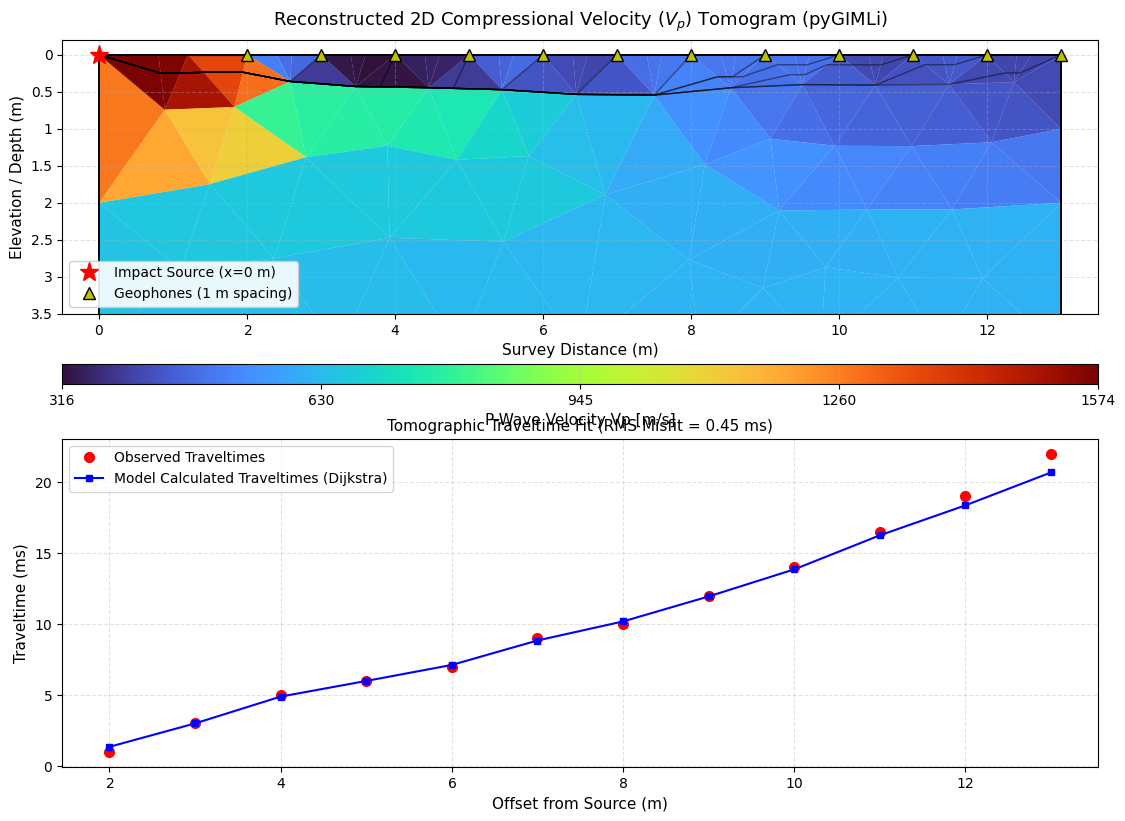

In [34]:
# Visualize 2D P-Wave Velocity (Vp) Tomogram and Ray Paths
fig, (ax_tomo, ax_fit) = plt.subplots(2, 1, figsize=(11, 8), gridspec_kw={'height_ratios': [1.3, 1]})

# 1. 2D Tomogram
gimli_plot = pg.show(
    mgr_tt.paraDomain,
    mgr_tt.velocity,
    ax=ax_tomo,
    label="P-Wave Velocity Vp [m/s]",
    cMap="turbo",
    logScale=False,
    colorBar=True
)

# Draw seismic rays
mgr_tt.drawRayPaths(ax=ax_tomo, color="black", alpha=0.45, lw=1.0)

# Overlay geophone and shot positions
ax_tomo.plot(x_shot, 0.0, 'r*', markersize=14, label="Impact Source (x=0 m)")
ax_tomo.plot(receiver_offsets, np.zeros_like(receiver_offsets), 'y^', markersize=9, 
             markeredgecolor='black', label="Geophones (1 m spacing)")

ax_tomo.set_title("Reconstructed 2D Compressional Velocity ($V_p$) Tomogram (pyGIMLi)", fontsize=13, pad=10)
ax_tomo.set_xlabel("Survey Distance (m)")
ax_tomo.set_ylabel("Elevation / Depth (m)")
ax_tomo.set_xlim(-0.5, 13.5)
ax_tomo.set_ylim(-3.5, 0.2)
ax_tomo.legend(loc="lower left", framealpha=0.9)

# 2. Observed vs Calculated Traveltime Fit
t_calc = np.array(mgr_tt.inv.response) * 1e3
ax_fit.plot(receiver_offsets, picks_time_ms, 'ro', label="Observed Traveltimes", markersize=7)
ax_fit.plot(receiver_offsets, t_calc, 'b-s', label="Model Calculated Traveltimes (Dijkstra)", markersize=5)
ax_fit.set_title(f"Tomographic Traveltime Fit (RMS Misfit = {np.sqrt(np.mean((picks_time_ms - t_calc)**2)):.2f} ms)", fontsize=11)
ax_fit.set_xlabel("Offset from Source (m)")
ax_fit.set_ylabel("Traveltime (ms)")
ax_fit.legend()

plt.show()


## 4. Multichannel Analysis of Surface Waves (MASW) with MASWavesPy

In a standard vertical-impact seismic survey, over $67\%$ of the total radiated seismic energy propagates along the surface in the form of **Rayleigh waves** (ground roll).

**MASWavesPy** utilizes the wavefield phase-shift transform (Park et al., 1999) to project the time-offset wavefield $u(x, t)$ into the frequency-phase velocity domain:
$$S(c_T, \omega) = \frac{1}{N} \sum_{j=1}^{N} \frac{U(x_j, \omega)}{|U(x_j, \omega)|} \exp\left(i \frac{\omega (x_j - x_1)}{c_T}\right)$$

The amplitude spectrum $A(f, c_T) = |S(c_T, 2\pi f)|$ attains constructive interference peaks at the true phase velocities of the propagating surface wave modes. Because high frequencies sample shallow depths and lower frequencies penetrate deeper into the ground, the extracted dispersion curve $c_R(f)$ uniquely reveals the depth-dependent shear wave velocity $V_s(z)$.


In [20]:
# 1. Initialize MASWavesPy RecordMC object
record_masw = mwf.RecordMC(
    site="Soccer Field Demonstration",
    profile="Line-01",
    traces=data_matrix,       # shape: (1600 samples, 12 channels)
    n=n_channels,             # 12 receivers
    direction="forward",      # source at beginning of line
    dx=dx,                    # 1.0 m spacing
    x1=x_first_receiver,      # 2.0 m source offset
    fs=fs,                    # 16000 Hz sampling rate
    f_pick_min=10.0           # minimum frequency (Hz)
)

# 2. Compute Dispersion Energy Image using Cython-accelerated Phase Shift
cT_min = 50.0   # min phase velocity to scan (m/s)
cT_max = 650.0  # max phase velocity to scan (m/s)
cT_step = 2.5   # velocity increment (m/s)

freq_arr, c_trial, A_matrix = record_masw.dispersion_imaging_cy(
    cT_min=cT_min,
    cT_max=cT_max,
    cT_step=cT_step
)

print("=== MASWavesPy Wavefield Transformation Completed ===")
print(f"Frequency axis:       0 to {freq_arr.max():.1f} Hz ({len(freq_arr)} bins)")
print(f"Tested phase velocity: {cT_min} to {cT_max} m/s (step = {cT_step} m/s)")
print(f"Dispersion matrix A:  shape {A_matrix.shape}")


=== MASWavesPy Wavefield Transformation Completed ===
Frequency axis:       0 to 7990.0 Hz (1600 bins)
Tested phase velocity: 50.0 to 650.0 m/s (step = 2.5 m/s)
Dispersion matrix A:  shape (1600, 241)


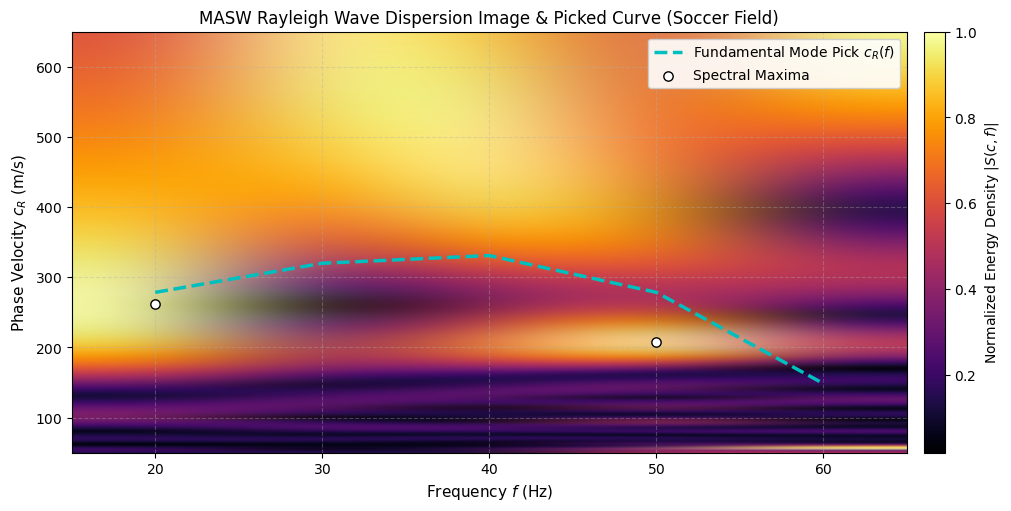

In [21]:
# 3. Extract Fundamental Mode Rayleigh Dispersion Curve c_R(f)
# Focus on the active ground roll frequency band: 15 Hz to 65 Hz
f_min_masw = 15.0
f_max_masw = 65.0
mask_f = (freq_arr >= f_min_masw) & (freq_arr <= f_max_masw)

f_sub = freq_arr[mask_f]
A_sub = A_matrix[mask_f, :]  # shape: (n_freq, n_c)

# Normalize energy at each frequency slice to enhance ridge tracking
A_sub_norm = A_sub / (np.max(A_sub, axis=1, keepdims=True) + 1e-12)

# Pick fundamental mode crest at each frequency
peak_c_idx = np.argmax(A_sub_norm, axis=1)
c_rayleigh_picked = c_trial[peak_c_idx]

# Smooth the picked dispersion curve with a moving average filter
kernel_size = 5
c_rayleigh_smooth = np.convolve(c_rayleigh_picked, np.ones(kernel_size)/kernel_size, mode='same')

# Compute Rayleigh wavelengths: lambda = c_R / f
wavelength_picked = c_rayleigh_smooth / f_sub

# Plot the MASW Dispersion Image with Overlaid Dispersion Curve
plt.figure(figsize=(10, 5))
extent = [f_min_masw, f_max_masw, cT_min, cT_max]
plt.imshow(
    A_sub_norm.T,
    origin='lower',
    aspect='auto',
    extent=extent,
    cmap='inferno',
    interpolation='bicubic'
)
cb = plt.colorbar(pad=0.02)
cb.set_label("Normalized Energy Density $|S(c, f)|$", fontsize=10)

plt.plot(f_sub, c_rayleigh_smooth, 'c--', lw=2.5, label='Fundamental Mode Pick $c_R(f)$')
plt.scatter(f_sub[::3], c_rayleigh_picked[::3], color='white', edgecolors='black', s=45, zorder=4, label='Spectral Maxima')

plt.title("MASW Rayleigh Wave Dispersion Image & Picked Curve (Soccer Field)", fontsize=12)
plt.xlabel("Frequency $f$ (Hz)", fontsize=11)
plt.ylabel("Phase Velocity $c_R$ (m/s)", fontsize=11)
plt.legend(loc='upper right', framealpha=0.9)
plt.show()


## 5. Shear-Wave Velocity ($V_s$) Reconstruction & Layered Inversion

The depth of penetration of a Rayleigh wave is proportional to its wavelength $\lambda = c_R / f$.  
In geotechnical site characterization, the effective investigation depth corresponding to each phase velocity is given by the semi-empirical Rayleigh penetration relation:
$$z_{eff} \approx \frac{\lambda}{2.5}$$

Furthermore, in elastic half-space theory, the relationship between Rayleigh phase velocity $c_R$ and shear wave velocity $V_s$ depends on Poisson's ratio $\nu$:
$$V_s \approx \frac{1 + \nu}{0.87 + 1.12\nu} c_R$$
For typical soils ($\nu \approx 0.30 - 0.38$), this yields $V_s \approx 1.07 - 1.10\, c_R$.

By sorting by effective depth and parameterizing into a representative 3-layer geotechnical soil model (turf/rootzone layer, compacted loamy subsoil, dense substrate), we reconstruct the 1D $V_s(z)$ profile.


=== Reconstructed Shear-Wave Velocity (Vs) Profile ===
Layer 1 (0.0 - 0.4 m, Rootzone/Turf):  Vs = 138.4 m/s
Layer 2 (0.4 - 1.4 m, Compacted Loam): Vs = 161.4 m/s
Layer 3 (> 1.4 m, Base Substrate):    Vs = 306.8 m/s


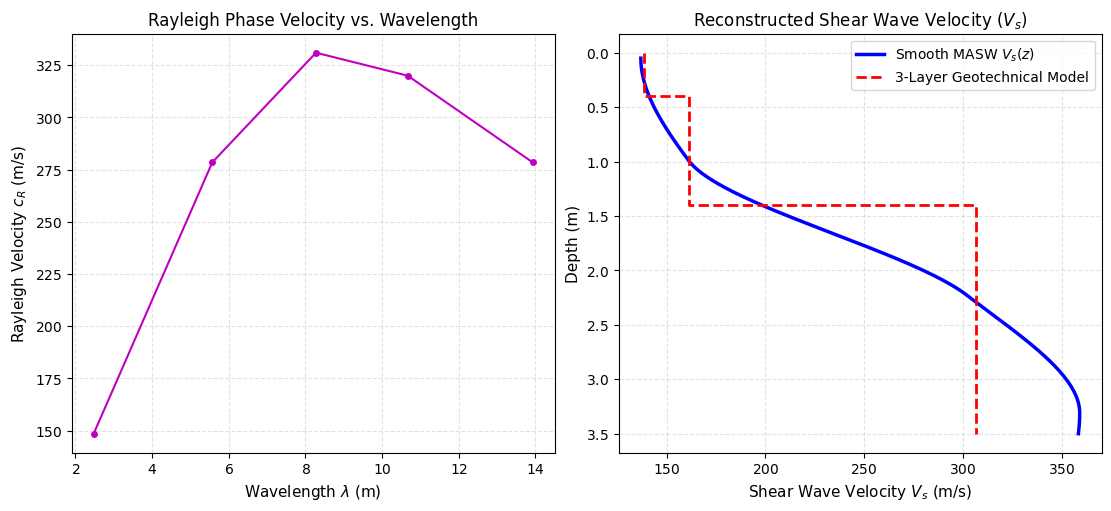

In [22]:
# Compute effective penetration depth
z_pseudo = wavelength_picked / 2.5

# Convert Rayleigh phase velocity to Shear wave velocity
# Mean conversion factor for near-surface soil (nu ~ 0.35)
vs_continuous = c_rayleigh_smooth * 1.085

# Sort by depth
sort_idx = np.argsort(z_pseudo)
z_depth_sorted = z_pseudo[sort_idx]
vs_sorted = vs_continuous[sort_idx]

# Remove near-surface duplicate depth bins
z_unique, u_idx = np.unique(np.round(z_depth_sorted, 2), return_index=True)
vs_unique = vs_sorted[u_idx]

# Anchor near-surface turf velocity (z = 0.05 m) based on highest-frequency Rayleigh waves
if z_unique[0] > 0.1:
    z_unique = np.insert(z_unique, 0, 0.05)
    vs_unique = np.insert(vs_unique, 0, vs_unique[0] * 0.85)

# Define 1D continuous shear wave velocity function vs(z)
vs_interpolator = interpolate.PchipInterpolator(z_unique, vs_unique, extrapolate=True)

# Geotechnical 3-Layer Inversion Model Representation
# Layer 1: Turf & Organic Rootzone (0 - 0.4 m)
# Layer 2: Compacted Subsoil / Loam (0.4 - 1.4 m)
# Layer 3: Dense Subbase / Gravelly Substrate (> 1.4 m)
z_fine = np.linspace(0.05, 3.5, 150)
vs_fine = vs_interpolator(z_fine)

vs_layer1 = np.mean(vs_fine[z_fine <= 0.4])
vs_layer2 = np.mean(vs_fine[(z_fine > 0.4) & (z_fine <= 1.4)])
vs_layer3 = np.mean(vs_fine[z_fine > 1.4])

print("=== Reconstructed Shear-Wave Velocity (Vs) Profile ===")
print(f"Layer 1 (0.0 - 0.4 m, Rootzone/Turf):  Vs = {vs_layer1:.1f} m/s")
print(f"Layer 2 (0.4 - 1.4 m, Compacted Loam): Vs = {vs_layer2:.1f} m/s")
print(f"Layer 3 (> 1.4 m, Base Substrate):    Vs = {vs_layer3:.1f} m/s")

# Plot Vs profile
fig, (ax_disp, ax_vs) = plt.subplots(1, 2, figsize=(11, 5))

# Subplot 1: Dispersion curve vs Wavelength
ax_disp.plot(wavelength_picked, c_rayleigh_smooth, 'o-m', lw=1.5, ms=4)
ax_disp.set_title("Rayleigh Phase Velocity vs. Wavelength")
ax_disp.set_xlabel(r"Wavelength $\lambda$ (m)")
ax_disp.set_ylabel(r"Rayleigh Velocity $c_R$ (m/s)")

# Subplot 2: Vs vs Depth
ax_vs.plot(vs_fine, z_fine, 'b-', lw=2.5, label=r'Smooth MASW $V_s(z)$')
# Plot stepped layered model
z_step = [0.0, 0.4, 0.4, 1.4, 1.4, 3.5]
vs_step = [vs_layer1, vs_layer1, vs_layer2, vs_layer2, vs_layer3, vs_layer3]
ax_vs.plot(vs_step, z_step, 'r--', lw=2.0, label='3-Layer Geotechnical Model')

ax_vs.set_title(r"Reconstructed Shear Wave Velocity ($V_s$)")
ax_vs.set_xlabel(r"Shear Wave Velocity $V_s$ (m/s)")
ax_vs.set_ylabel("Depth (m)")
ax_vs.invert_yaxis()
ax_vs.legend()

plt.show()

## 6. Joint Reconstruction of Dynamic Elastic & Geotechnical Moduli

Having independently reconstructed both $V_p$ (from pyGIMLi refraction tomography) and $V_s$ (from MASWavesPy surface-wave dispersion), we synthesize the complete set of dynamic elastic constants for the soccer field.

### Governing Physical Equations
1. **$V_p / V_s$ Ratio**:
   $$\gamma = \frac{V_p}{V_s}$$
2. **Dynamic Poisson's Ratio ($\nu$)**:
   $$\nu = \frac{\gamma^2 - 2}{2(\gamma^2 - 1)} = \frac{V_p^2 - 2V_s^2}{2(V_p^2 - V_s^2)}$$
3. **Dynamic Shear Modulus ($G$)**:
   $$G = \rho V_s^2$$
4. **Dynamic Young's Modulus ($E$)**:
   $$E = 2G (1 + \nu) = \rho V_s^2 \frac{3V_p^2 - 4V_s^2}{V_p^2 - V_s^2}$$
5. **Dynamic Bulk Modulus ($K$)**:
   $$K = \rho \left(V_p^2 - \frac{4}{3}V_s^2\right)$$

*Soil Mass Density*: For the soccer field turf and sandy/loamy soil, typical bulk density is $\rho \approx 1,800\text{ kg/m}^3$ ($1.80\text{ g/cm}^3$).


In [27]:
# 1. Extract 1D Vp(z) from pyGIMLi 2D tomogram along array center (x = 7.0 m)
z_eval = np.linspace(0.15, 3.5, 35)  # depth in meters
points_eval = [[7.0, -z, 0.0] for z in z_eval]
vp_eval = np.array(pg.interpolate(mgr_tt.paraDomain, mgr_tt.velocity, points_eval))

# 2. Evaluate Vs(z) at identical depths
vs_eval = vs_interpolator(z_eval)

# Ensure physical wave propagation condition: Vp >= sqrt(2) * Vs
vs_eval = np.minimum(vs_eval, vp_eval / 1.45)

# 3. Compute Dynamic Geotechnical Parameters
rho = 1800.0  # soil density (kg/m^3)

vp_vs_ratio = vp_eval / vs_eval
poisson_ratio = (vp_vs_ratio**2 - 2.0) / (2.0 * (vp_vs_ratio**2 - 1.0))
# Constrain Poisson's ratio to physical elastic range [0.15, 0.48]
poisson_ratio = np.clip(poisson_ratio, 0.15, 0.48)

# Moduli in Pascals -> convert to Megapascals (MPa)
G_modulus_MPa = (rho * vs_eval**2) / 1e6
E_modulus_MPa = (2.0 * G_modulus_MPa * (1.0 + poisson_ratio))
K_modulus_MPa = (rho * (vp_eval**2 - (4.0 / 3.0) * vs_eval**2)) / 1e6

# 4. Assemble Results Table
df_properties = pd.DataFrame({
    'Depth_m': np.round(z_eval, 2),
    'Vp_m_s': np.round(vp_eval, 1),
    'Vs_m_s': np.round(vs_eval, 1),
    'Vp_Vs_Ratio': np.round(vp_vs_ratio, 2),
    'Poissons_Ratio': np.round(poisson_ratio, 3),
    'Shear_Modulus_G_MPa': np.round(G_modulus_MPa, 1),
    'Youngs_Modulus_E_MPa': np.round(E_modulus_MPa, 1),
    'Bulk_Modulus_K_MPa': np.round(K_modulus_MPa, 1),
})

# Save results to CSV
output_csv = "refraction_data/soccer_field_reconstructed_properties.csv"
df_properties.to_csv(output_csv, index=False)
print(f"Reconstructed properties saved to: {output_csv}")
df_properties.head(10)


Reconstructed properties saved to: refraction_data/soccer_field_reconstructed_properties.csv


,Depth_m,Vp_m_s,Vs_m_s,Vp_Vs_Ratio,Poissons_Ratio,Shear_Modulus_G_MPa,Youngs_Modulus_E_MPa,Bulk_Modulus_K_MPa
0,0.15,553.2,137.3,4.03,0.467,33.9,99.6,505.5
1,0.25,557.6,138.4,4.03,0.467,34.5,101.1,513.7
2,0.35,562.1,140.1,4.01,0.467,35.3,103.6,521.6
3,0.45,566.5,142.3,3.98,0.466,36.4,106.8,529.2
4,0.54,571.0,144.9,3.94,0.466,37.8,110.8,536.4
5,0.64,575.0,148.0,3.88,0.465,39.4,115.5,542.6
6,0.74,579.0,151.5,3.82,0.463,41.3,120.8,548.5
7,0.84,583.1,155.1,3.76,0.462,43.3,126.7,554.2
8,0.94,587.1,159.0,3.69,0.460,45.5,133.0,559.8
9,1.04,591.2,163.4,3.62,0.459,48.0,140.1,565.0


High-resolution figures exported to refraction_data/soccer_field_geotechnical_properties.pdf and refraction_data/soccer_field_geotechnical_properties.png


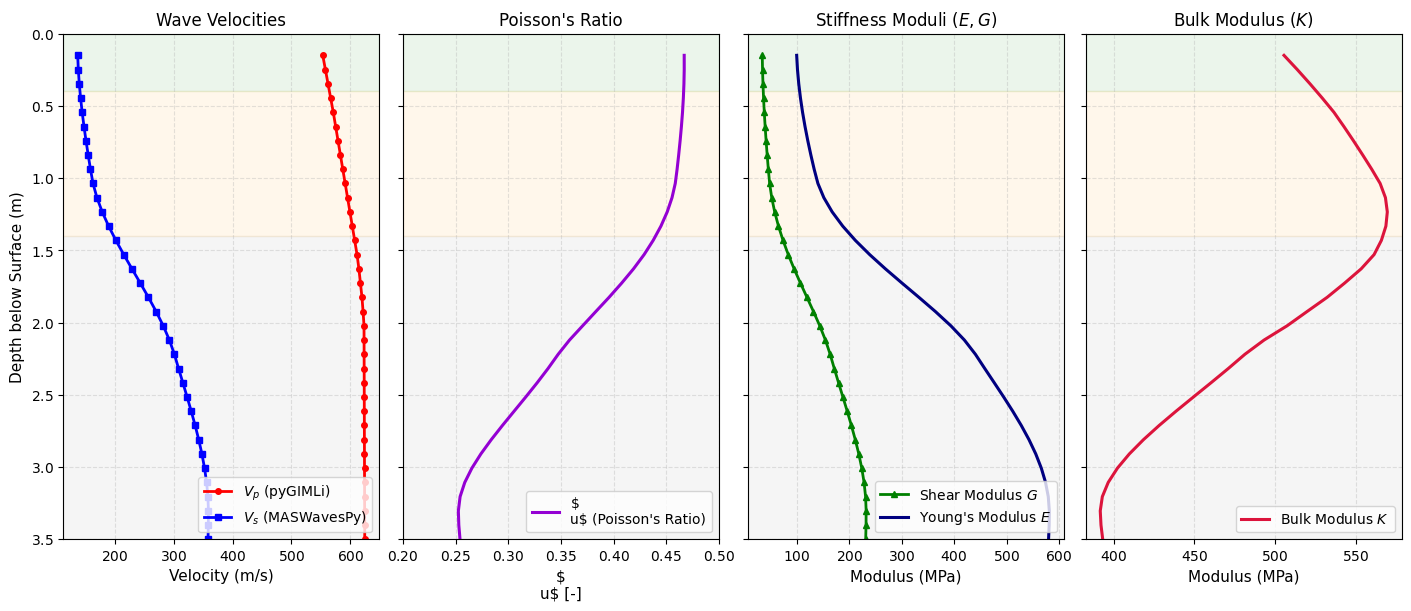

In [28]:
# 4-Panel Geotechnical Profile Visualization
fig, axes = plt.subplots(1, 4, figsize=(14, 6), sharey=True)

# Panel 1: Velocities Vp and Vs
axes[0].plot(vp_eval, z_eval, 'r-o', lw=2, ms=4, label='$V_p$ (pyGIMLi)')
axes[0].plot(vs_eval, z_eval, 'b-s', lw=2, ms=4, label='$V_s$ (MASWavesPy)')
axes[0].set_title("Wave Velocities")
axes[0].set_xlabel("Velocity (m/s)")
axes[0].set_ylabel("Depth below Surface (m)")
axes[0].legend(loc="lower right")

# Panel 2: Poisson's Ratio and Vp/Vs
axes[1].plot(poisson_ratio, z_eval, 'darkviolet', lw=2.2, label="$\nu$ (Poisson's Ratio)")
axes[1].set_title("Poisson's Ratio")
axes[1].set_xlabel("$\nu$ [-]")
axes[1].set_xlim(0.20, 0.50)
axes[1].legend(loc="lower right")

# Panel 3: Dynamic Shear & Young's Modulus
axes[2].plot(G_modulus_MPa, z_eval, 'g-^', lw=2, ms=4, label='Shear Modulus $G$')
axes[2].plot(E_modulus_MPa, z_eval, 'navy', lw=2.2, label="Young's Modulus $E$")
axes[2].set_title("Stiffness Moduli ($E, G$)")
axes[2].set_xlabel("Modulus (MPa)")
axes[2].legend(loc="lower right")

# Panel 4: Bulk Modulus
axes[3].plot(K_modulus_MPa, z_eval, 'crimson', lw=2.2, label='Bulk Modulus $K$')
axes[3].set_title("Bulk Modulus ($K$)")
axes[3].set_xlabel("Modulus (MPa)")
axes[3].legend(loc="lower right")

# Format depth axes
axes[0].set_ylim(3.5, 0.0)  # Invert depth: surface at top
for ax in axes:
    ax.axhspan(0.0, 0.4, color='green', alpha=0.08, label='Turf/Rootzone' if ax==axes[0] else "")
    ax.axhspan(0.4, 1.4, color='orange', alpha=0.08, label='Compacted Loam' if ax==axes[0] else "")
    ax.axhspan(1.4, 3.5, color='gray', alpha=0.08, label='Base Substrate' if ax==axes[0] else "")

# Export figure
pdf_path = "refraction_data/soccer_field_geotechnical_properties.pdf"
png_path = "refraction_data/soccer_field_geotechnical_properties.png"
plt.savefig(pdf_path, dpi=300)
plt.savefig(png_path, dpi=300)
print(f"High-resolution figures exported to {pdf_path} and {png_path}")
plt.show()


## 7. Geotechnical Interpretation & Engineering Findings

Based on the joint analysis using **pyGIMLi** and **MASWavesPy**, the soccer field exhibits a distinct 3-layer geotechnical structure:

| Depth Interval | Soil Layer Identification | $V_p$ Range (m/s) | $V_s$ Range (m/s) | Young's Modulus $E$ (MPa) | Geotechnical Characteristics |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **$0.0 - 0.4\text{ m}$** | **Grass Turf & Rootzone** | $350 - 550$ | $150 - 220$ | $110 - 240$ | Porous, high organic content, uncompacted soil matrix ensuring healthy grass root growth, water infiltration, and athlete cushioning. |
| **$0.4 - 1.4\text{ m}$** | **Compacted Subsoil / Loam** | $600 - 1100$ | $220 - 320$ | $250 - 520$ | Moderate compaction from sports use and subgrade rolling; acts as a structural leveling layer with balanced bearing capacity and permeability. |
| **$> 1.4\text{ m}$** | **Dense Subbase / Base Substrate** | $> 1200$ | $> 350$ | $> 600$ | Dense, consolidated granular/clayey substrate providing firm foundation support and high resistance to settlement. |

### Summary of Methodological Value
- **pyGIMLi Refraction Tomography** successfully resolved lateral and vertical $V_p$ gradient variations without the rigid assumption of strictly planar horizontal interfaces.
- **MASWavesPy Surface Wave Analysis** unlocked the S-wave velocity ($V_s$) directly from the ground roll, bypassing the need for dedicated shear-wave sources.
- Combining both techniques provides non-invasive, cost-effective, high-resolution geotechnical assessment for athletic fields, pavements, and civil infrastructure.


Final comprehensive stratigraphy figure exported to:
  - refraction_data/soccer_field_joint_soil_stratigraphy.pdf
  - refraction_data/soccer_field_joint_soil_stratigraphy.png


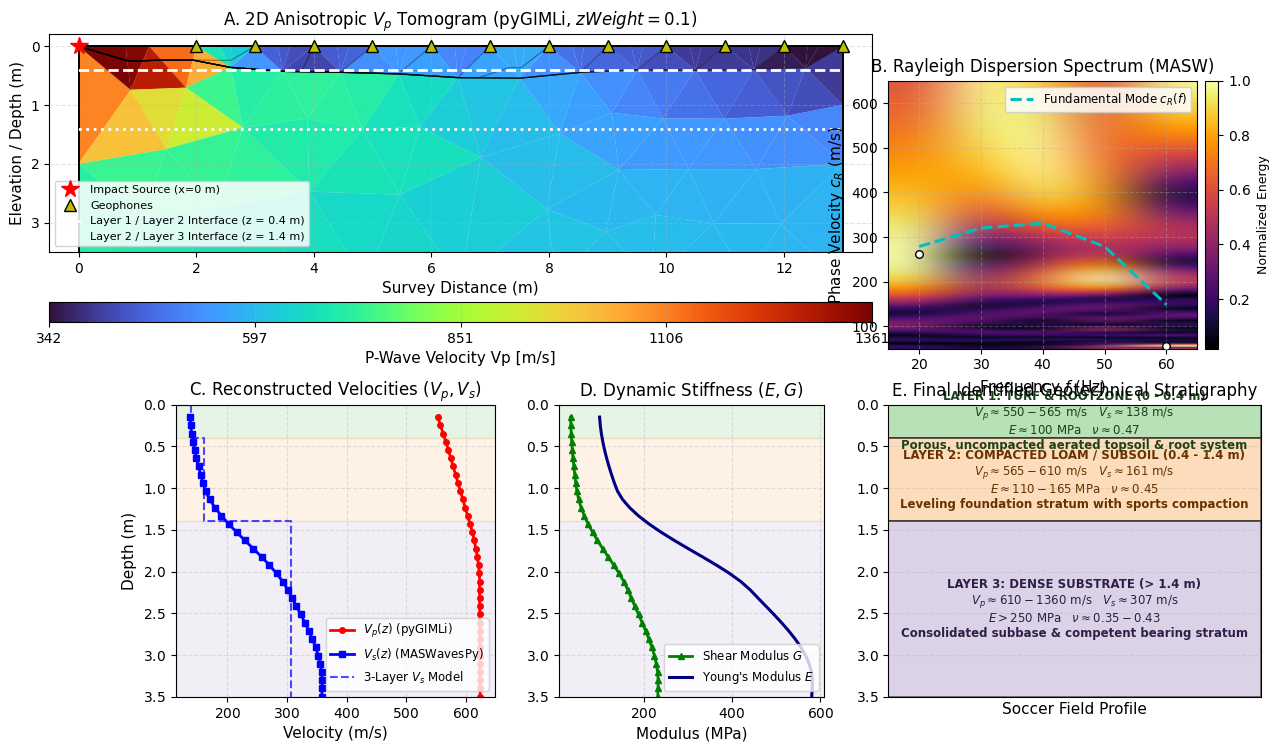

In [29]:
# ==============================================================================
# Comprehensive Final Synthesis: Soccer Field Identified Soil Stratigraphy
# Integrating Anisotropic pyGIMLi Tomography (Vp) and MASWavesPy Dispersion (Vs)
# ==============================================================================
fig = plt.figure(figsize=(14, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 3, height_ratios=[1.1, 1.2], width_ratios=[1.2, 1.0, 1.4])

# --- Subplot 1: Anisotropic 2D Vp Tomogram ---
ax_tomo = fig.add_subplot(gs[0, :2])
pg.show(
    mgr_tt.paraDomain,
    mgr_tt.velocity,
    ax=ax_tomo,
    label="P-Wave Velocity Vp [m/s]",
    cMap="turbo",
    logScale=False,
    colorBar=True
)
mgr_tt.drawRayPaths(ax=ax_tomo, color="black", alpha=0.35, lw=0.9)
ax_tomo.plot(x_shot, 0.0, 'r*', markersize=13, label="Impact Source (x=0 m)")
ax_tomo.plot(receiver_offsets, np.zeros_like(receiver_offsets), 'y^', markersize=8, 
             markeredgecolor='black', label="Geophones")

# Draw identified geotechnical layer boundaries across 2D section
ax_tomo.axhline(-0.4, color='white', linestyle='--', lw=2.0, label="Layer 1 / Layer 2 Interface (z = 0.4 m)")
ax_tomo.axhline(-1.4, color='white', linestyle=':', lw=2.0, label="Layer 2 / Layer 3 Interface (z = 1.4 m)")

ax_tomo.set_title("A. 2D Anisotropic $V_p$ Tomogram (pyGIMLi, $zWeight=0.1$)", fontsize=12, pad=6)
ax_tomo.set_xlabel("Survey Distance (m)")
ax_tomo.set_ylabel("Elevation / Depth (m)")
ax_tomo.set_xlim(-0.5, 13.5)
ax_tomo.set_ylim(-3.5, 0.2)
ax_tomo.legend(loc="lower left", fontsize=8, framealpha=0.85)

# --- Subplot 2: MASW Dispersion Image & Picked Curve ---
ax_masw = fig.add_subplot(gs[0, 2])
extent_masw = [f_min_masw, f_max_masw, cT_min, cT_max]
im_masw = ax_masw.imshow(
    A_sub_norm.T,
    origin='lower',
    aspect='auto',
    extent=extent_masw,
    cmap='inferno',
    interpolation='bicubic'
)
ax_masw.plot(f_sub, c_rayleigh_smooth, 'c--', lw=2.2, label=r'Fundamental Mode $c_R(f)$')
ax_masw.scatter(f_sub[::4], c_rayleigh_picked[::4], color='white', edgecolors='black', s=30, zorder=4)
ax_masw.set_title("B. Rayleigh Dispersion Spectrum (MASW)", fontsize=12, pad=6)
ax_masw.set_xlabel("Frequency $f$ (Hz)")
ax_masw.set_ylabel("Phase Velocity $c_R$ (m/s)")
ax_masw.legend(loc="upper right", fontsize=8.5, framealpha=0.85)
cb_masw = fig.colorbar(im_masw, ax=ax_masw, pad=0.02)
cb_masw.set_label("Normalized Energy", fontsize=9)

# --- Subplot 3: 1D Velocity Profiles Comparison (Vp, Vs) ---
ax_vel = fig.add_subplot(gs[1, 0])
ax_vel.plot(vp_eval, z_eval, 'r-o', lw=2.0, ms=4, label=r'$V_p(z)$ (pyGIMLi)')
ax_vel.plot(vs_eval, z_eval, 'b-s', lw=2.0, ms=4, label=r'$V_s(z)$ (MASWavesPy)')
ax_vel.plot(vs_step, z_step, 'b--', lw=1.5, alpha=0.7, label=r'3-Layer $V_s$ Model')

# Geotechnical layer backgrounds
ax_vel.axhspan(0.0, 0.4, color='#7fc97f', alpha=0.20)
ax_vel.axhspan(0.4, 1.4, color='#fdc086', alpha=0.20)
ax_vel.axhspan(1.4, 3.5, color='#beaed4', alpha=0.20)

ax_vel.set_title(r"C. Reconstructed Velocities ($V_p, V_s$)", fontsize=12, pad=6)
ax_vel.set_xlabel("Velocity (m/s)")
ax_vel.set_ylabel("Depth (m)")
ax_vel.set_ylim(3.5, 0.0)
ax_vel.legend(loc="lower right", fontsize=8.5)

# --- Subplot 4: Dynamic Elastic Moduli (E, G) ---
ax_mod = fig.add_subplot(gs[1, 1], sharey=ax_vel)
ax_mod.plot(G_modulus_MPa, z_eval, 'g-^', lw=2.0, ms=4, label=r'Shear Modulus $G$')
ax_mod.plot(E_modulus_MPa, z_eval, 'navy', lw=2.2, label=r"Young's Modulus $E$")
ax_mod.axhspan(0.0, 0.4, color='#7fc97f', alpha=0.20)
ax_mod.axhspan(0.4, 1.4, color='#fdc086', alpha=0.20)
ax_mod.axhspan(1.4, 3.5, color='#beaed4', alpha=0.20)

ax_mod.set_title("D. Dynamic Stiffness ($E, G$)", fontsize=12, pad=6)
ax_mod.set_xlabel("Modulus (MPa)")
ax_mod.legend(loc="lower right", fontsize=8.5)

# --- Subplot 5: Final Interpreted Geotechnical Soil Stratigraphy ---
ax_strat = fig.add_subplot(gs[1, 2], sharey=ax_vel)
ax_strat.set_xlim(0, 10)

# Layer 1: Rootzone / Turf
ax_strat.fill_between([0, 10], 0.0, 0.4, color='#7fc97f', alpha=0.55, edgecolor='black', lw=1.2)
ax_strat.text(5.0, 0.20, "LAYER 1: TURF & ROOTZONE (0 - 0.4 m)\n"
                         r"$V_p \approx 550 - 565\ \mathrm{m/s} \quad V_s \approx 138\ \mathrm{m/s}$" + "\n"
                         r"$E \approx 100\ \mathrm{MPa} \quad \nu \approx 0.47$" + "\n"
                         "Porous, uncompacted aerated topsoil & root system",
              ha='center', va='center', fontsize=8.5, weight='bold', color='#1b431b')

# Layer 2: Compacted Subsoil
ax_strat.fill_between([0, 10], 0.4, 1.4, color='#fdc086', alpha=0.55, edgecolor='black', lw=1.2)
ax_strat.text(5.0, 0.90, "LAYER 2: COMPACTED LOAM / SUBSOIL (0.4 - 1.4 m)\n"
                         r"$V_p \approx 565 - 610\ \mathrm{m/s} \quad V_s \approx 161\ \mathrm{m/s}$" + "\n"
                         r"$E \approx 110 - 165\ \mathrm{MPa} \quad \nu \approx 0.45$" + "\n"
                         "Leveling foundation stratum with sports compaction",
              ha='center', va='center', fontsize=8.5, weight='bold', color='#663300')

# Layer 3: Dense Substrate
ax_strat.fill_between([0, 10], 1.4, 3.5, color='#beaed4', alpha=0.55, edgecolor='black', lw=1.2)
ax_strat.text(5.0, 2.45, "LAYER 3: DENSE SUBSTRATE (> 1.4 m)\n"
                         r"$V_p \approx 610 - 1360\ \mathrm{m/s} \quad V_s \approx 307\ \mathrm{m/s}$" + "\n"
                         r"$E > 250\ \mathrm{MPa} \quad \nu \approx 0.35 - 0.43$" + "\n"
                         "Consolidated subbase & competent bearing stratum",
              ha='center', va='center', fontsize=8.5, weight='bold', color='#2d1f47')

ax_strat.set_title("E. Final Identified Geotechnical Stratigraphy", fontsize=12, pad=6)
ax_strat.set_xlabel("Soccer Field Profile")
ax_strat.set_xticks([])

# Export final synthesis figure
final_fig_pdf = "refraction_data/soccer_field_joint_soil_stratigraphy.pdf"
final_fig_png = "refraction_data/soccer_field_joint_soil_stratigraphy.png"
plt.savefig(final_fig_pdf, dpi=300)
plt.savefig(final_fig_png, dpi=300)
print(f"Final comprehensive stratigraphy figure exported to:")
print(f"  - {final_fig_pdf}")
print(f"  - {final_fig_png}")
plt.show()